# Flujo y transporte conservativo de la especie $c_1= Ca^{2+}$.

**Descripción**.

En esta notebook se plantea el problema de flujo de agua subterránea y transporte conservativo de la especie química $c_1 = Ca^{2+}$ y se resuelve usando MODFLOW 6 (GWF y GWT) en combinación de las herramientas de **FloPy**.

<a href="https://github.com/luiggix/RTWMA">RTWMA</a> © 2024-2026 by <a href="https://www.geofisica.unam.mx">IGF-UNAM</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/nc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">

# Importación de bibliotecas y definición de rutas

In [1]:
# ---> Bibliotecas que se usarán en este ejemplo
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import flopy
import xmf6

Definimos un diccionario con información de la ruta al ejecutable de MODFLOW y con los nombres de los modelos de flujo y transporte así como los directorios del espacio de trabajo.

In [2]:
## ---> Variables de entorno
with open('../env.json', 'r', encoding='utf-8') as file:
    env = json.load(file)
env["ROOT_DIR"] = os.getcwd() # Agregamos el dir raíz

xmf6.nice_print("Environment variables", env)

## ---> Diccionario con información de rutas y archivos
paths = dict(
    # Ejecutable de MODFLOW 6
    mf6_exe = env["MF6EXE"],
    #
    # Nombre de los modelos y espacios de trabajo
    flow_name = "flow",
    flow_ws = "io_mf6/c1/gwf",
    tran_name = "transport",
    tran_ws = "io_mf6/c1/gwt"
)
xmf6.nice_print("Paths, files and more ...", paths)


Environment variables
―――――――――――――――――――――
  MF6EXE = /Users/luiggi/GitSites/00_NEAT/RTWMA/bin/macosarm/mf6
  MF6DLL = /Users/luiggi/GitSites/00_NEAT/RTWMA/bin/macosarm/libmf6.dylib
  RT_WMA = /Users/luiggi/GitSites/00_NEAT/RTWMA/benchmarks/00_RT_EXE/bin/TR_1D_oper.exe
  RT_COM = /Users/luiggi/GitSites/00_NEAT/RTWMA/benchmarks/00_RT_EXE/bin/interfaz_remix.exe
ROOT_DIR = /Users/luiggi/GitSites/00_NEAT/RTWMA/benchmarks/01_CT_gypsum_1D
―――――――――――――――――――――

Paths, files and more ...
―――――――――――――――――――――――――
  mf6_exe = /Users/luiggi/GitSites/00_NEAT/RTWMA/bin/macosarm/mf6
flow_name = flow
  flow_ws = io_mf6/c1/gwf
tran_name = transport
  tran_ws = io_mf6/c1/gwt
―――――――――――――――――――――――――


# Planteamiento del problema.

El dominio es una columna 1D de longitud $L = 30 \text{ (m)}$ en dirección $x$ representando un acuífero de espesor y ancho unitarios. Sobre este dominio ocurren dos procesos acoplados:

- Flujo de agua subterránea, gobernado por la carga hidráulica $h(x,t)$.
- Transporte de soluto, gobernado por la concentración $c_1(x,t)$, que se
  mueve por advección (arrastrado por el flujo de agua) y dispersión
  hidrodinámica.

El campo de flujo (carga $h$ y velocidad $v$) controla el transporte pero el soluto no modifica la densidad ni la viscosidad del agua.

El problema se va a resolver en un periodo de $40$ días con un paso de tiempo constante de $1$ día ($40$ pasos de tiempo).

## Modelo de flujo de agua subterránea.

Para un acuífero 1D confinado con conductividad hidráulica $K_x$ y coeficiente de almacenamiento específico $S_s$, la ecuación de flujo es:

$$
S_s \frac{\partial h}{\partial t} = \frac{\partial}{\partial x}
\left( K_x \frac{\partial h}{\partial x} \right) + q_s(x,t)
$$

donde $q_s(x,t)$ representa fuentes o sumideros volumétricos de agua por
unidad de volumen (p. ej. un pozo).

### Condiciones iniciales y de condiciones de frontera:

<figure>
  <img src="../figures/c1_flujo.svg" width=600px alt="dominio de estudio y condiciones" />
  <figcaption>Figura 1. Condiciones iniciales y de frontera para el flujo. </figcaption>
</figure>

**Condiciones de frontera:**

$$
\begin{eqnarray}
\left.\frac{\partial h}{\partial x}\right|_{(0,t)} & = & 0.0
\qquad\text{(flujo nulo en } x=0\text{)} \\
h\Big|_{(x_{_{L}},t)} & = & 1.0 \qquad\text{(carga fija en } x=x_{_{L}}\text{)}
\end{eqnarray}
$$

**Condición inicial:** 

$$
h(x,t_0) = 1.0 \qquad\text{(m)}
$$

<div class="alert alert-info">
    
**NOTA**.

En MODFLOW 6 se utiliza $Q^\prime_s$ para representar el flujo volumétrico por unidad de volumen en una fuente o sumidero y $SS$ para representar el almacenamiento específico. En este documento usaremos $q_s$ y $S_s$ para dichas cantidades respectivamente.

</div>

## Modelo de transporte de soluto.

Para la especie $c_1$ con porosidad $\theta$, coeficiente de dispersión hidrodinámica $D_{xx}$ y descarga específica $q$ la ecuación de transporte se escribe como:

$$
- \frac{\partial (\theta c_1)}{\partial t}
- \frac{\partial (q_x c_1)}{\partial x}
+ \frac{\partial}{\partial x}\left(\theta D_{xx} \frac{\partial c_1}{\partial x}\right)
+ q_s c_s = 0
$$

con $D_{xx} = \alpha_L |v_x| + D^{*}$ ($\alpha_L$: dispersividad longitudinal,
$D^{*}$: difusión molecular efectiva), $v_x = q_x / \theta $ ($v_x$: velocidad de
poro de flujo de agua) y $c_s$ es la concentración volumétrica de soluto en la fuente/sumidero.

### Condiciones iniciales y de condiciones de frontera:

<figure>
  <img src="../figures/c1_transporte.svg" width=600px alt="dominio de estudio y condiciones" />
  <figcaption>Figura 2. Condiciones iniciales y de frontera para el transporte. El dominio es de tamaño $L = 30 \text{ (m)}$ y será dividido en $30$ celdas de $1\;\text{(m)}$ cada una. En la celda $11$ se impone un pulso de concentración mayor a la de todo el dominio; en este caso la distancia del inicio del dominio al centro de la celda $11$ es $x_p = 10.5$ (m). </figcaption>
</figure>


**Condiciones de frontera:**

$$
q_x c_1 - D_x \frac{\partial c_1}{\partial x}  = q_{inf} c_{inf} \qquad\text{ en } x=0
$$

$$
D_x \frac{\partial c_1}{\partial x} = 0
\qquad\text{ en } x=L
$$

**Condición inicial:**

$$
c_1(x,t_0) = 1.0000329371 \quad \forall\, x \neq x_{p}
$$
$$
c_1(x_{p}, t_0) = 200.000000165
$$

En el instante inicial la concentración es igual a un valor de $1.0000329371$ 
en todo el dominio, excepto en el punto $x_{p}$ donde existe un valor 
en dicha celda de $200.000000165$ que representa una masa de soluto
ya presente en el medio (p. ej. un derrame o inyección previa) que a partir
de $t_0$ comenzará a migrar y dispersarse bajo la acción del flujo.


# Modelado numérico con MODFLOW 6.

## Definición de datos.

### Discretización espacial.

El dominio se discretiza en $30$ celdas equiespaciadas como se muestra en la figura 4.

<figure>
  <img src="../figures/spatial_dis.svg" width=600px alt="dominio de estudio y condiciones" />
  <figcaption>Figura 3. El espacio se discretiza en 30 celdas. Se resaltan las celdas de la frontera y aquellas donde se tiene una condición inicial de concentración alta. </figcaption>
</figure>

La siguiente tabla muestra los valores para la discretización espacial definidos en términos de la notación de MODFLOW 6 y FloPy. La columna **Variable** indica la(s) variable(s) donde se almacena cada valor en la implementación.

|Parámetro | Valor | Unidades | Variable |
|---:|:---:|:---:|:---|
|Length of system (cols) | $30.0$ | m | |
|Number of layers | $1$ | | `dis["nlay"]`|
|Number of rows | $1$ | | `dis["nrow"]`|
|Number of columns | $30$ | | `dis["ncol"]`|
|Column width | $1.0$ | m | `dis["delr"]`|
|Row width | $1.0$ | m | `dis["delc"]`|
|Top of the model | $1.0$ | m | `dis["top"]`|
|Layer bottom elevation | $0$ | m | `dis["botm"]`|

In [3]:
## ---> Discretización espacial
L = 30 # Longitud del dominio
nlay = 1
nrow = 1
ncol = 30
delr = L / ncol # 1.0
delc = 1.0
top  = 1.0
botm = 0.0

## ---> Diccionario con información de la discretización espacial
dis = {
    'length_units' : "meters",
    'nlay': nlay, 
    'nrow': nrow, 
    'ncol': ncol,
    'delr': delr, 
    'delc': delc, 
    'top' : top, 
    'botm': botm 
}
xmf6.nice_print("Spatial discretization", dis)


Spatial discretization
――――――――――――――――――――――
length_units = meters
        nlay = 1
        nrow = 1
        ncol = 30
        delr = 1.0
        delc = 1.0
         top = 1.0
        botm = 0.0
――――――――――――――――――――――


### Discretización temporal.

Como se mencionó en el planteamiento del problema, se va a resolver en un periodo de $40$ días con un paso de tiempo constante de $1$ día ($40$ pasos de tiempo). Sin embargo, debido a que el flujo se mantiene constante durante toda la simulación, se utiliza un solo paso de tiempo de $40$ días para resolver el flujo. 

|Parámetro | Valor| Unidades | Variable |
|---:|:---:|:---:|:---|
|Number of stress periods (NPER) | $1$ | | `tdis["nper"]` |
|Total time | $40$ | days | `tdis["perioddata"][0][0]` |
|Number of time steps (NSTP) | $1$ | | `tdis["perioddata"][0][1]` |
|Multiplier (TSMULT)| $1$ | | `tdis["perioddata"][0][2]` |


<div class="alert alert-info">
    
**NOTA**.

El valor del parámetro NSTP será cambiado a $40$ cuando se resuelva el transporte.
</div>

In [4]:
## ---> Diccionario con información de la discretización del tiempo para el flujo 
tdis = {
    'units': "days",
    'nper' : 1,
    'perioddata': [(40.0, 1, 1.0)] # PERLEN, NSTP, TSMULT
}
xmf6.nice_print("Time discretization (flow)", tdis)


Time discretization (flow)
――――――――――――――――――――――――――
     units = days
      nper = 1
perioddata = ―― data array ――
           = (40.0, 1, 1.0)
――――――――――――――――――――――――――


### Parámetros físicos.

Para resolver el problema necesitamos definir varios parámetros físicos. Para ello tomaremos en cuenta que el flujo es estacionario, por lo que solo se resuelve una vez en el lapso de $40$ días, esto implica además que no se requiere definir el coeficiente de almacenamiento específico $S_s$. Recordemos que en la celda $1$ se agrega un pozo de inyección, que es coherente con el hecho de que ahí se especifica una descarga específica $q_{inf}$ y una concentración de entrada $c_{inf} = 1.000329$, esto representa el agua que ingresa al sistema y empuja el soluto hacia $x_{_{L}}$. Las condiciones iniciales y de frontera se describen en las figuras $1$ y $2$. En la siguiente tabla se describen todos los parámetros requeridos, comenzando primero con los de flujo y posteriormente con los de transporte.

|Parámetro | Símbolo | Valor | Unidades | Variable |
|---:|:--:|:---:|:---:|:---|
|Initial head | $h(x, t_0)$| $1.0$ | m | `phys["initial_head"]` |
|Head boundary condition (type I) | $h(L, t)$ | $1.0$ | m | `phys["bc_head_t1"]` |
|Hydraulic conductivity | $K_x$ |$1.0$| m d$^{-1}$ | `phys["hydraulic_conductivity"]` |
|Specific discharge | $q_s$ |$0.2$| m d$^{-1}$ | `phys["specific_discharge"]` |
|Source concentration | $c_s$ | $1.0000329371$| unitless | `phys["source_concentration"][0]` |
|Well inyection | $q_s c_s$ |  | m d$^{-1}$ | `phys["well"]`|
|Porosity | $\theta$ | $0.5$ | unitless |  `phys["porosity"]` |
|Initial concentration | $c_1(x, t_0)$ |$1.0000329371$ | unitless | `phys["initial_concentration"]` |
|Initial concentration pulse | $c_1(x_{p}, t_0)$ |$200.0$ | unitless | `phys["initial_concentration"][11]` |
|Longitudinal Dispersivity | $\alpha_L$ |$0.5$ | m  | `phys["longitudinal_dispersivity"]` |
|Dispersion coefficient | $D_{xx}$ | $1.0$ | m$^{2}$ d$^{-1}$| `phys["dispersion_coefficient"]` |

<div class="alert alert-info">
    
**NOTA**.

En MODFLOW para imponer la condición de tercer tipo, se agrega un pozo con una concentración de entrada; en este caso $q_{inf} c_{inf} \equiv q_s c_s$.
</div>

In [5]:
## ---> Condición inicial para el transporte
x_pulse = 10.5
i_pulse = int(x_pulse / delr) # 10

# Arreglo para la condición inicial
c1_ini = np.full((nlay,nrow,ncol), 1.0000329371) # En todo el dominio
c1_ini[0, 0, i_pulse] = 200.000000165  # Pulso en x_11

xmf6.nice_print("Array info: c1")
xmf6.info_array(c1_ini)

## ---> Diccionario para los parámetros físicos
phys = {} # Inicializamos el diccionario 

## ---> Datos para el modelo de flujo
phys["initial_head"] = 1.0
phys["bc_head_t1"] = {
        "pname": "CHD-1", 
        "stress_period_data": [[(0, 0, dis['ncol'] - 1), 1.0],],
    }
phys["hydraulic_conductivity"] = 1.0
phys["specific_discharge"] = 0.2
phys["source_concentration"] = 1.0000329371
q = phys["specific_discharge"] * dis['delc'] * dis['delr'] * (dis['top'] - dis['botm'])
phys["well"] = {
    "pname": "WEL-1",
    "stress_period_data": [[(0, 0, 0), q, phys["source_concentration"]],],
    "auxiliary": ["CONCENTRATION"]
}

## ---> Datos para el modelo de transporte
phys["porosity"] = 0.5
phys["initial_concentration"] = c1_ini
phys["longitudinal_dispersivity"] = 0.5 
phys["SSM"] = [(phys["well"]["pname"], 
               "AUX", 
               phys["well"]["auxiliary"][0]),]

xmf6.nice_print("Physical parameters", phys)


Array info: c1
――――――――――――――

 tipo  : <class 'numpy.ndarray'> 
 dtype : float64 
 dim   : 3 
 shape : (1, 1, 30) 
 size(bytes) : 8 
 size(elements) : 30

Physical parameters
―――――――――――――――――――
             initial_head = 1.0
               bc_head_t1 = {'pname': 'CHD-1', 'stress_period_data': [[(0, 0, 29), 1.0]]}
   hydraulic_conductivity = 1.0
       specific_discharge = 0.2
     source_concentration = 1.0000329371
                     well = {'pname': 'WEL-1', 'stress_period_data': [[(0, 0, 0), 0.2, 1.0000329371]], 'auxiliary': ['CONCENTRATION']}
                 porosity = 0.5
    initial_concentration = ―― data array ――
                          = [[  1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
    1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
  200.00000016   1.00003294   1.00003294   1.00003294   1.00003294
    1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
    1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
 

## Construcción del modelo de flujo con GWF.

Para realizar una simulación de flujo con GWF de MODFLOW 6 es necesario construir una estructura usando las siguientes clases de FloPy: `flopy.mf6.MFSimulation`, `flopy.mf6.ModflowTdis`, `flopy.mf6.ModflowIms` y `flopy.mf6.ModflowGwf`. A partir de estas clases se crean objetos con los atributos requeridos por la simulación. En la siguiente celda se realiza esta implementación:

In [6]:
## ---> Creación del objeto de la simulación de flujo
o_sim = flopy.mf6.MFSimulation(
    sim_name = paths["flow_name"], 
    sim_ws = paths["flow_ws"], 
    exe_name = paths["mf6_exe"], 
    version="mf6"
)

## ---> Creación del objeto de la discretización del tiempo
o_tdis = flopy.mf6.ModflowTdis(
    o_sim,
    time_units = tdis["units"],
    nper = tdis["nper"],
    perioddata = tdis["perioddata"],
)

## ---> Creación del objeto de la solución del sistema lineal
o_ims = flopy.mf6.ModflowIms(
    o_sim
)

## ---> Creación del objeto del modelo de flujo
o_gwf = flopy.mf6.ModflowGwf(
    o_sim, 
    modelname = paths["flow_name"], 
    save_flows = True
)

### Paquetes.

Para resolver el problema de flujo antes planteado se requiere de agregar paquetes al modelo que está representado por el objeto `o_gwf`. En este caso requerimos los siguientes paquetes:

- `DIS`: Discretización espacial de tipo estructurada.
- `NPF`: Propiedades del flujo, particularmente la conductividad hidráulica $K_x$.
- `IC`: Definición de las condiciones iniciales de la carga hidráulica.
- `CHD`: Condición de frontera de carga hidráulica fija $h(x_{_{L}},t)=1.0$.
- `WEL`: Pozo de inyección de $q_s c_s$ en $x_{_{1}}$.
- `OC` : Definición de los archivos para almacenar los resultados de la simulación.
- No se define el paquete `STO` debido a que el flujo se resuelve en régimen
  permanente.
- El límite izquierdo ($x=0$) no recibe ninguna condición de frontera, por
  lo que MODFLOW 6 le asigna flujo nulo por defecto:
  $\partial h/\partial x(0,t)=0$ se cumple automáticamente.

In [7]:
## ---> Agregamos el paquete DIS para la discretización espacial estructurada
o_dis = flopy.mf6.ModflowGwfdis(
    o_gwf,
    length_units = dis["length_units"],
    nlay = dis["nlay"], 
    nrow = dis["nrow"], 
    ncol = dis["ncol"],
    delr = dis["delr"], 
    delc = dis["delc"], 
    top  = dis["top"], 
    botm = dis["botm"],
)

## ---> Agregamos el paquete NPF para las prop. del flujo
o_npf = flopy.mf6.ModflowGwfnpf(
    o_gwf,
    k = phys["hydraulic_conductivity"], 
    icelltype = 0, 
    save_specific_discharge = True,
    save_saturation = True
)

## ---> Agregamos el paquete IC para las condiciones iniciales
o_ic = flopy.mf6.ModflowGwfic(
    o_gwf, 
    strt = phys["initial_head"]
)

## ---> Agregamos el paquete CHD para definir la carga fija (condición de frontera)
o_chd = flopy.mf6.ModflowGwfchd(
    o_gwf,
    stress_period_data = phys["bc_head_t1"]["stress_period_data"],
    pname = phys["bc_head_t1"]["pname"],
)

## ---> Agregamos el paquete WEL para definir un pozo de inyección
## Pozo de inyeccion en x1 (con concentracion auxiliar para el acople con GWT)
o_wel = flopy.mf6.ModflowGwfwel(
    o_gwf,
    stress_period_data = phys["well"]["stress_period_data"], 
    auxiliary = phys["well"]["auxiliary"],
    pname = phys["well"]["pname"],
)

## ---> Agregamos el paquete OC para almacenar la salida
oc_gwf = flopy.mf6.ModflowGwfoc(
    o_gwf,
    head_filerecord = f"{paths["flow_name"]}.hds",
    budget_filerecord = f"{paths["flow_name"]}.bud",
    saverecord = [("HEAD", "ALL"), ("BUDGET", "ALL")],
)

### Escritura de archivos y ejecución.

In [8]:
## ---> Escritura de los archivos de entrada para la simulación de flujo
o_sim.write_simulation(silent = False)

## ---> Ejecución de la simulación de flujo.
o_sim.run_simulation(silent = False)

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model flow...
    writing model name file...
    writing package dis...
    writing package npf...
    writing package ic...
    writing package chd-1...
INFORMATION: maxbound in ('', 'chd', 'dimensions') changed to 1 based on size of stress_period_data
    writing package wel-1...
INFORMATION: maxbound in ('', 'wel', 'dimensions') changed to 1 based on size of stress_period_data
    writing package oc...
FloPy is using the following executable to run the model: ../../../../../bin/macosarm/mf6
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                            VERSION 6.6.1 02/10/2025

        MODFLOW 6 compiled Feb 10 2025 17:05:58 with GCC version 13.3.0

This software has been approved for release by the U.S. Geological 
Survey (USGS). Although the software has been subjected t

(True, [])

### Revisión de resultados.

Los resultados de la simulación de flujo quedan almacenados en archivos con extensión `.hds` y `.bud` que están en formato binario. FloPy ofrece herramientas para extraer esta información y visualizarla. La biblioteca xmf6 encapsula estas herramientas en funciones que permite un uso más simple. A continuación extraemos la información de la carga hidráulica $h$ y de la descarga específica $q$.

In [9]:
## ---> Objeto para acceder a los resultados de la carga hidráulica.
o_head = o_gwf.output.head()

## ---> Tiempos calculados para el flujo.
times_h = np.array(o_head.get_times())

## ---> Recuperamos la carga hidráulica del paso 40.
head = o_head.get_data(totim=40)[0, 0, :]

## ---> Objeto para acceder a los resultados de la descarga específica.
budget = o_gwf.output.budget()

## ---> Recuperamos la descarga específica del paso 40.
spdis = budget.get_data(totim=40, text="DATA-SPDIS")[0]
qx, qy, qz = flopy.utils.postprocessing.get_specific_discharge(spdis, o_gwf)

## ---> Recuperamos las coordenadas de los centros de las celdas de la malla
x, y, z = o_gwf.modelgrid.xyzcellcenters

## ---> Diccionario para imprimir la información en pantalla
flow_dict = dict(
    xcoord = x,
    times = [times_h],
    head = [head],
    qx = qx[:,0],
)
xmf6.nice_print("Head", flow_dict)


Head
――――
xcoord = ―― data array ――
       = [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]
 times = ―― data array ――
       = [40.]
  head = ―― data array ――
       = [6.8 6.6 6.4 6.2 6.  5.8 5.6 5.4 5.2 5.  4.8 4.6 4.4 4.2 4.  3.8 3.6 3.4
 3.2 3.  2.8 2.6 2.4 2.2 2.  1.8 1.6 1.4 1.2 1. ]
    qx = ―― data array ――
       = [0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2]
――――


## Construcción del modelo de transporte conservativo con GWT

De igual manera que en el caso del flujo, para realizar la simulación del transporte conservativo se debe construir una estructura similar. Debido a que esta es una simulación separada de la del flujo, reutilizaremos algunos objetos con atributos diferentes. Comenzamos con la discretización del tiempo; en este caso se realizan $40$ pasos de un día cada uno, entonces el diccionario `tdis` lo modificamos como sigue:

In [10]:
## ---> Discretización del tiempo para el transporte
tdis = {
    'units': "days",
    'nper' : 1,
    'perioddata': [(40.0, 40, 1.0)] #PERLEN, NSTP, TSMULT
}
xmf6.nice_print("Time discretization (transport)", tdis)


Time discretization (transport)
―――――――――――――――――――――――――――――――
     units = days
      nper = 1
perioddata = ―― data array ――
           = (40.0, 40, 1.0)
―――――――――――――――――――――――――――――――


Entonces la estructura inicial de la simulación se realiza como sigue:

In [11]:
## ---> Creación del objeto de la simulación de transporte
o_sim = flopy.mf6.MFSimulation(
    sim_name = paths["tran_name"], 
    sim_ws = paths["tran_ws"], 
    exe_name = paths["mf6_exe"], 
    version="mf6"
)

## ---> Creación del objeto de la discretización del tiempo
## OJO: aquí cambio el número de pasos de simulación.
o_tdis = flopy.mf6.ModflowTdis(
    o_sim,
    time_units = tdis["units"],
    nper = tdis["nper"],
    perioddata = tdis["perioddata"],
)

## ---> Creación del objeto de la solución del sistema lineal
## En este caso se requiere de un "solver" para sistemas no simétricos
o_ims = flopy.mf6.ModflowIms(
    o_sim,
    complexity="SIMPLE",
    linear_acceleration="BICGSTAB",
    outer_dvclose=1e-8,
    inner_dvclose=1e-8,
)

## ---> Creación del objeto del modelo de transporte
o_gwt = flopy.mf6.ModflowGwt(
    o_sim, 
    modelname = paths["tran_name"], 
    save_flows = True
)

### Paquetes.

Para resolver el problema de transporte necesitamos agregar paquetes al modelo que está representado por el objeto `o_gwt`. En este caso se agregan los siguientes:

- `DIS`: Discretización espacial de tipo estructurada. Se usa la misma que se usó para el flujo.
- `IC`: Condición inicial $c_1(x,t_0)$ que consiste en un valor constante en todo el dominio
  y el pulso puntual en $x_{_{11}}$.
- `ADV` : Calcula el arrastre del soluto por el agua.
  El esquema `TVD` es de segundo orden y limita las oscilaciones numéricas. Evita la difusión numérica excesiva del esquema upstream y los sobre/subvalores del esquema centrado.
- `DSP` : Representa la dispersión hidrodinámica $D = \alpha_L|v_x| + D^*$:
    - `alh` = $0.5$ es la dispersividad longitudinal ($\alpha_L$).
    - `ath1` = $0.5$ es la dispersividad transversal horizontal. En 1D no tiene efecto práctico.
    - `xt3d_off` = `True` desactiva la formulación XT3D y usa la de diferencias finitas estándar, suficiente en una malla ortogonal.
- `MST`: Define la porosidad $\theta = 0.5$. Este paquete maneja el término de acumulación $\partial(\theta c_1)/\partial t$. No se incluyen decaimiento ni sorción, por lo que el soluto es conservativo.
- En $x_{_{L}}$ MODFLOW 6 aplica de forma natural un
  gradiente dispersivo nulo en la celda de salida, es decir
  $D_x\,\partial c_1/\partial x(L,t)=0$ se cumple automáticamente.
- `FMI` : Enlaza los modelos GWF y GWT. Le indica a GWT que lea los archivos de la simulación del flujo:
    - las cargas (`GWFHEAD`) y
    - los caudales (`GWFBUDGET`). 
- `SSM`: vincula la concentración auxiliar (`CONCENTRATION`) del pozo `WEL-1` con el transporte, requerido por MODFLOW 6 cuando el modelo de flujo tiene paquetes de frontera. Dice con qué concentración entra el agua de cada fuente del flujo, en este caso el agua inyectada trae $c_1(x_{_{1}},t)=1.000329$. Sin este paquete, el agua inyectada entraría con concentración cero.

In [12]:
## ---> Agregamos el paquete DIS para la discretización espacial estructurada
o_dis = flopy.mf6.ModflowGwtdis(
    o_gwt,
    length_units = dis["length_units"],
    nlay = dis["nlay"], 
    nrow = dis["nrow"], 
    ncol = dis["ncol"],
    delr = dis["delr"], 
    delc = dis["delc"], 
    top  = dis["top"], 
    botm = dis["botm"],
)

## ---> Agregamos el paquete IC para las condiciones iniciales
o_ic = flopy.mf6.ModflowGwtic(
    o_gwt, 
    strt = phys["initial_concentration"]
)

## ---> Agregamos el paquete ADV para seleccionar el esquema de advección
o_adv = flopy.mf6.ModflowGwtadv(
    o_gwt, 
    scheme = "TVD"
)

## ---> Agregamos el paquete DSP para seleccionar el modelo de dispersión
o_dsp = flopy.mf6.ModflowGwtdsp(
    o_gwt, 
    xt3d_off = True,
    alh = phys["longitudinal_dispersivity"], 
    ath1 = phys["longitudinal_dispersivity"], 
)

## ---> Agregamos el paquete MST para definir la porosidad
o_mst = flopy.mf6.ModflowGwtmst(
    o_gwt, 
    porosity = phys["porosity"]
)

## ---> Agregamos el paquete FMI para enlazar la solución del flujo con la de transporte
path_flow = os.path.join(os.getcwd(), paths["flow_ws"], paths["flow_name"])
o_fmi = flopy.mf6.ModflowGwtfmi(
    o_gwt, 
    packagedata = [("GWFHEAD", f"{path_flow}.hds", None),
                   ("GWFBUDGET", f"{path_flow}.bud", None),
                  ],
    flow_imbalance_correction=True
)

## ---> Agregamos el paquete SSM para vincular la concentración auxiliar del 
## pozo WEL-1 con el transporte
o_ssm = flopy.mf6.ModflowGwtssm(
    o_gwt, 
    sources = phys["SSM"]
)

## ---> Agregamos el paquete OC para almacenar la salida
oc_gwt = flopy.mf6.ModflowGwtoc(
    o_gwt,
    concentration_filerecord=f"{paths["tran_name"]}.ucn",
    budget_filerecord=f"{paths["tran_name"]}.cbc",
    saverecord=[("CONCENTRATION", "ALL"), ("BUDGET", "ALL")],
)

### Escritura de archivos y ejecución.

In [13]:
## ---> Escritura de los archivos de entrada para la simulación.
o_sim.write_simulation(silent = False)

## ---> Ejecución de la simulación de flujo.
o_sim.run_simulation(silent = False)

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model transport...
    writing model name file...
    writing package dis...
    writing package ic...
    writing package adv...
    writing package dsp...
    writing package mst...
    writing package fmi...
    writing package ssm...
    writing package oc...
FloPy is using the following executable to run the model: ../../../../../bin/macosarm/mf6
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                            VERSION 6.6.1 02/10/2025

        MODFLOW 6 compiled Feb 10 2025 17:05:58 with GCC version 13.3.0

This software has been approved for release by the U.S. Geological 
Survey (USGS). Although the software has been subjected to rigorous 
review, the USGS reserves the right to update the software as needed 
pursuant to further analysis and review. No warranty, expressed

(True, [])

### Revisión de resultados.

Los resultado de la simulación de transporte quedan almacenados en archivos con extensión `.ucn` y `.cbc` en formato binario. En este caso usamos las herramientas que ofrece FloPy ofrece para extraer esta información.

In [14]:
## ---> Objeto para recuperar los resultados del transporte
o_conc = o_gwt.output.concentration()

## ---> Recuperamos los pasos de tiempo calculados
times_c = np.array(o_conc.get_times())

## ---> Recuperamos la información de todos los pasos de la concentración
c1 = o_conc.get_alldata()[:, 0, 0, :]

## ---> Diccionario para imprimir la información en pantalla
tran_dict = dict(
    xcoord = x,
    times = [times_c],
    conc = [c1[39]] # último paso
)
xmf6.nice_print("c1 concentration", tran_dict)


c1 concentration
――――――――――――――――
xcoord = ―― data array ――
       = [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]
 times = ―― data array ――
       = [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37. 38. 39. 40.]
  conc = ―― data array ――
       = [ 1.0000359   1.00003991  1.00005341  1.00009326  1.00020574  1.00051106
  1.00130649  1.00329121  1.00802386  1.01878565  1.04207164  1.08991102
  1.18302408  1.35435275  1.65173194  2.13759861  2.88317012  3.95516911
  5.3954275   7.19728554  9.28622231 11.51349971 13.66912297 15.51374977
 16.82173756 17.38358055 17.25843674 16.61838584 15.39177217 13.73308012]
――――――――――――――――


# Visualización de resultados.

La visualización de los resutados de flujo y transporte los realizamos usando FloPy en combinación con matplotlib.

In [15]:
## ---> Usamos LaTeX para los tectos de la figura.
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  # Uses standard Computer Modern font
    "font.serif": ["Computer Modern Roman"],
})

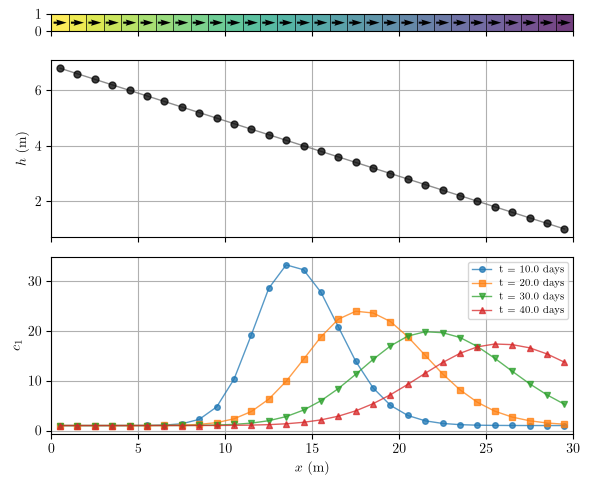

In [16]:
## ---> Definición de la figura. Se construyen tres gráficas 
fig, (ax1, ax2, ax3) = plt.subplots(3,1, sharex = True, figsize =(6,5),
                                    height_ratios=[0.1, 0.5, 0.5])

## ---> Gráfica 1. Carga hidráulica y descarga específica sobre la malla
ax1.set_aspect('equal')
pmv = flopy.plot.PlotMapView(model = o_gwf, ax = ax1)
pmv.plot_grid(colors = 'k', lw = 0.5, ls="-")
pmv.plot_array(head, cmap = "viridis", alpha=0.5)
pmv.plot_vector(qx, qy, scale=40, pivot="mid", width=0.004, normalize=True, color="k")

## ---> Gráfica 2. Carga hidráulica vs posición
ax2.plot(x[0], head, marker="o", lw =1.0, c = "dimgray", label = 'Head', 
         mec="black", mfc="black", markersize="5", alpha = 0.75, )
ax2.set_xlim(0, 30)
ax2.set_ylabel("$h$ (m)")
ax2.grid()

## ---> Gráfica 3. Concentración para diferentes pasos de tiempo
marker = ["o", "s", "v", "^"] 
for i, t in enumerate(times_c[9::10]):
    ax3.plot(x[0], c1[int(t-1)], ls ="-", lw = 1.0, label=f"t = {t} days", zorder=2,
             marker = marker[i], markersize="4", alpha = 0.75)

ax3.set_xlabel("$x$ (m)")
ax3.set_ylabel("$c_1$")
ax3.legend(fontsize=7)
ax3.grid()

plt.tight_layout()
plt.show()

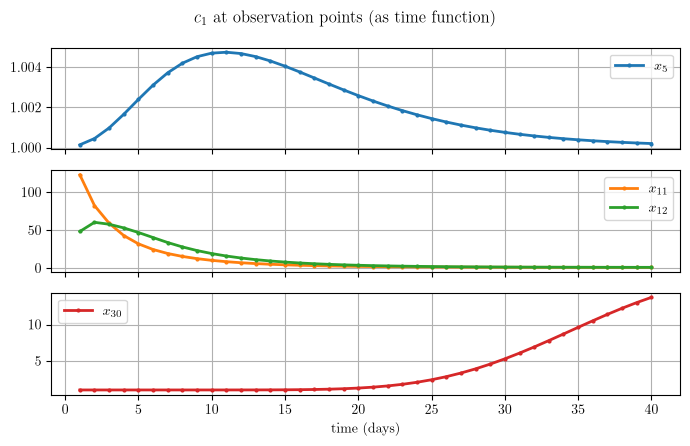

In [17]:
c_5  = np.array([c1[int(t-1)][4]  for t in times_c])
c_11 = np.array([c1[int(t-1)][10] for t in times_c])
c_12 = np.array([c1[int(t-1)][11] for t in times_c])
c_30 = np.array([c1[int(t-1)][29] for t in times_c])

fig, ax = plt.subplots(3,1, sharex = True, figsize=(7, 4.5))
fig.suptitle("$c_1$ at observation points (as time function)")

ax[0].plot(times_c, c_5, lw=2,marker="o",markersize="2",c="C0",label="$x_5$")
ax[0].grid()
ax[0].legend()

ax[1].plot(times_c, c_11, lw=2,marker="o",markersize="2",c="C1",label="$x_{11}$")
ax[1].plot(times_c, c_12, lw=2,marker="o",markersize="2",c="C2",label="$x_{12}$")
ax[1].grid()
ax[1].legend()

ax[2].plot(times_c, c_30, lw=2,marker="o",markersize="2",c="C3",label="$x_{30}$")
ax[2].grid()
ax[2].legend()
ax[2].set_xlabel("time (days)")
plt.tight_layout()
plt.show()

# Referencias.

* Langevin, C. D., Hughes, J. D., Provost, A. M., Russcher, M. J., & Panday, S. (2023). MODFLOW as a configurable Multi‐Model Hydrologic Simulator. Ground Water. https://doi.org/10.1111/gwat.13351.
